<a href="https://colab.research.google.com/github/ZiyuCao421/CP5408-TR3-Cyber-Security-Strategy/blob/main/CP5408_Practical_5_DJI_Aligned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CP5408 Practical 5: Preparing and Describing Security Data — DJI-aligned version

This notebook supports the Week 5 worksheet and the continuing DJI case study. It has two parts:

- **Sections 1–2** reproduce the seminar's 24-week firewall change-request example and demonstrate how outliers affect descriptive statistics.
- **Sections 3–6** clean and analyse the lecturer-provided **synthetic** security-incident dataset, then calculate example ARO and low / likely / high SLE and ALE values.

**Important boundary:** The firewall values and the 36 incident records are teaching data, not DJI operational records. Do not replace the synthetic records with invented DJI incidents or describe the resulting statistics as DJI's actual incident rate or loss. The final note connects the categories to DJI risks only as cautious analogies.

You do not need to write code. Run the cells from top to bottom. As specified in the worksheet, the only cell you need to change for the cleaning experiment is the **decision settings** cell in Section 4. Figures and the CSV summary are saved in the notebook's working directory.

## 0. Setup

Run this cell first.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

SAVE_FIGURES = True
dollars = FuncFormatter(lambda v, _: f'${v:,.0f}')

def finish(fig_name):
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(f'{fig_name}.png', dpi=200, bbox_inches='tight')
    plt.show()

def describe(values, label):
    # Descriptive statistics from the Week 5 seminar, for one list of numbers.
    s = pd.Series(values, dtype='float')
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    return pd.Series({
        'Count': s.count(),
        'Mode': ', '.join(f'{m:g}' for m in s.mode()),
        'Median': q2,
        'Mean': s.mean(),
        'Minimum': s.min(),
        'Maximum': s.max(),
        'Range': s.max() - s.min(),
        'Quartile 1': q1,
        'Quartile 3': q3,
        'Interquartile range': q3 - q1,
        'Standard deviation': s.std(),
    }, name=label)

## 1. The seminar dataset: weekly firewall change requests

These are the 24 weekly values used in the seminar. The cell calculates the measures of central tendency (mode, median, mean) and dispersion (range, quartiles, interquartile range, standard deviation). Check them against the seminar slides.

In [2]:
change_requests = [19, 20, 21, 21, 22, 22, 22, 26, 27, 27, 27, 27,
                   28, 28, 29, 31, 34, 35, 35, 37, 41, 46, 61, 65]

original = describe(change_requests, 'Seminar data (24 weeks)')
original.to_frame()

,Seminar data (24 weeks)
Count,24
Mode,27
Median,27.50
Mean,31.29
Minimum,19.00
Maximum,65.00
Range,46.00
Quartile 1,22.00
Quartile 3,35.00
Interquartile range,13.00


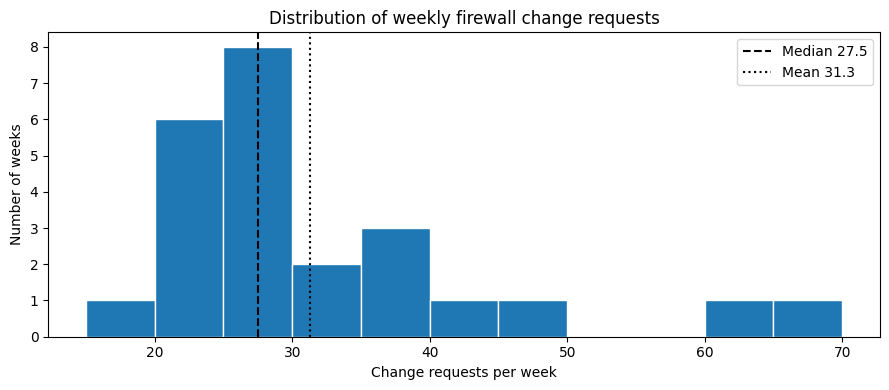

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(change_requests, bins=range(15, 71, 5), edgecolor='white')
ax.axvline(np.median(change_requests), color='black', linestyle='--', label=f'Median {np.median(change_requests):g}')
ax.axvline(np.mean(change_requests), color='black', linestyle=':', label=f'Mean {np.mean(change_requests):.1f}')
ax.set_xlabel('Change requests per week')
ax.set_ylabel('Number of weeks')
ax.set_title('Distribution of weekly firewall change requests')
ax.legend()
finish('p5_fig1_change_requests')

## 2. What do outliers do?

The seminar asked what happens if two unusual weeks are added: one with **0** requests and one with **200**. Compare the two columns. Which measures barely move, and which move a lot?

In [4]:
with_outliers = describe(change_requests + [0, 200], 'With 0 and 200 added')
comparison = pd.concat([original, with_outliers], axis=1)
comparison

,Seminar data (24 weeks),With 0 and 200 added
Count,24,26
Mode,27,27
Median,27.50,27.50
Mean,31.29,36.58
Minimum,19.00,0.00
Maximum,65.00,200.00
Range,46.00,200.00
Quartile 1,22.00,22.00
Quartile 3,35.00,35.00
Interquartile range,13.00,13.00


## 3. A messy incident dataset

The records below are **synthetic teaching data**. For the exercise, imagine they were assembled from public incident reports and an insurer's claims summary, covering **40 comparable organisations over 5 years (2021–2025)**. They are not records supplied by DJI. Because records from multiple sources can be inconsistent, this dataset intentionally includes common data-quality problems.

Run the cells and look for: category names written in different ways; costs recorded as text, with symbols, as `N/A`, blank, or zero; severity recorded on two different scales; and at least one very unusual value.

In [5]:
N_ORGANISATIONS = 40
N_YEARS = 5

records = [
    # id,   year, category (as recorded),        cost (as recorded), downtime_h, severity (as recorded)
    ('I01', 2021, 'Ransomware',                  420000,       96,   'High'),
    ('I02', 2021, 'phishing',                    18000,        4,    'Low'),
    ('I03', 2021, 'Data breach',                 310000,       12,   'High'),
    ('I04', 2021, 'Third-party outage',          90000,        20,   'Medium'),
    ('I05', 2021, 'Phishing',                    25000,        6,    2),
    ('I06', 2021, 'Device compromise',           200000,       48,   4),
    ('I07', 2022, 'ransomware ',                 610000,       120,  5),
    ('I08', 2022, 'Phishing',                    '32,000',     8,    'Low'),
    ('I09', 2022, 'data-breach',                 780000,       30,   'High'),
    ('I10', 2022, 'Phishing',                    0,            2,    1),
    ('I11', 2022, 'Third party outage',          150000,       36,   'Medium'),
    ('I12', 2022, 'Firmware compromise',         340000,       72,   'High'),
    ('I13', 2022, 'RANSOMWARE',                  '$380,000',   80,   'High'),
    ('I14', 2023, 'Phishing / account takeover', 12000,        3,    'Low'),
    ('I15', 2023, 'Data Breach',                 '$1,100,000', 40,   5),
    ('I16', 2023, 'Ransomware',                  950000,       160,  'High'),
    ('I17', 2023, 'Outage (supplier)',           0,            10,   'Low'),
    ('I18', 2023, 'phishing',                    45000,        None, 'Medium'),
    ('I19', 2023, 'Device compromise',           'N/A',        60,   'High'),
    ('I20', 2023, 'Ransomware',                  'N/A',        200,  'High'),
    ('I21', 2023, 'Data breach',                 450000,       16,   4),
    ('I22', 2024, 'Phishing',                    '',           5,    'Low'),
    ('I23', 2024, 'Ransomware',                  1250000,      240,  5),
    ('I24', 2024, 'Third-party outage',          210000,       48,   'High'),
    ('I25', 2024, 'Phishing',                    28000,        6,    2),
    ('I26', 2024, 'data breach',                 'unknown',    None, 'Medium'),
    ('I27', 2024, 'Ransomware',                  4800000,      720,  5),
    ('I28', 2024, 'Device compromise',           510000,       96,   'High'),
    ('I29', 2024, 'Phishing',                    52000,        12,   'Medium'),
    ('I30', 2025, 'Data breach',                 260000,       10,   'Medium'),
    ('I31', 2025, 'Third-party outage',          120000,       30,   3),
    ('I32', 2025, 'ransomware',                  520000,       110,  'High'),
    ('I33', 2025, 'Phishing',                    22000,        4,    'Low'),
    ('I34', 2025, 'Data breach',                 640000,       24,   'High'),
    ('I35', 2025, 'Third-party outage',          '75,000',     18,   'Medium'),
    ('I36', 2025, 'Firmware compromise',         280000,       64,   4),
]
raw = pd.DataFrame(records, columns=['incident_id', 'year', 'category', 'cost', 'downtime_hours', 'severity'])
print(f'{len(raw)} records')
raw.head(12)

36 records


,incident_id,year,category,cost,downtime_hours,severity
0,I01,2021,Ransomware,420000,96.00,High
1,I02,2021,phishing,18000,4.00,Low
2,I03,2021,Data breach,310000,12.00,High
3,I04,2021,Third-party outage,90000,20.00,Medium
4,I05,2021,Phishing,25000,6.00,2
5,I06,2021,Device compromise,200000,48.00,4
6,I07,2022,ransomware,610000,120.00,5
7,I08,2022,Phishing,"32,000",8.00,Low
8,I09,2022,data-breach,780000,30.00,High
9,I10,2022,Phishing,0,2.00,1


In [6]:
print('Category labels as recorded:')
print(raw['category'].value_counts().to_string())
print()
print('Cost values that are not plain numbers:')
print(raw.loc[~raw['cost'].apply(lambda v: isinstance(v, (int, float))), ['incident_id', 'cost']].to_string(index=False))
print()
print('Severity values as recorded:', sorted(raw['severity'].astype(str).unique()))

Category labels as recorded:
category
Phishing                       7
Ransomware                     5
Third-party outage             4
Data breach                    4
Device compromise              3
phishing                       2
Firmware compromise            2
ransomware                     1
data-breach                    1
Third party outage             1
RANSOMWARE                     1
Phishing / account takeover    1
Data Breach                    1
Outage (supplier)              1
data breach                    1
ransomware                     1

Cost values that are not plain numbers:
incident_id       cost
        I08     32,000
        I13   $380,000
        I15 $1,100,000
        I19        N/A
        I20        N/A
        I22           
        I26    unknown
        I35     75,000

Severity values as recorded: ['1', '2', '3', '4', '5', 'High', 'Low', 'Medium']


## 4. Decision settings, then clean

Some cleaning steps have an obvious right answer (for example, `ransomware ` and `RANSOMWARE` are the same category). Others are **judgement calls**, and different defensible choices give different results. Set your choices in the next cell, run the rest of the notebook, and record the results in your worksheet. Then change one setting and run again.

| Setting | Options | What it means |
|---|---|---|
| `ZERO_COST_RULE` | `'missing'` or `'keep'` | Is a recorded cost of 0 a real zero-cost incident, or does it mean the cost was never recorded? |
| `MISSING_COST_RULE` | `'drop'` or `'median'` | Leave incidents with no cost out of the cost statistics, or fill them with the median cost for their category? |
| `OUTLIER_RULE` | `'keep'`, `'remove'` or `'cap'` | Keep unusually large costs, remove them, or cap them at the outlier threshold? (Threshold: quartile 3 + 1.5 × interquartile range, within each category.) |

In [7]:
# ---- DECISION SETTINGS: this is the only cell you need to edit ----
ZERO_COST_RULE = 'missing'      # 'missing' or 'keep'
MISSING_COST_RULE = 'drop'      # 'drop' or 'median'
OUTLIER_RULE = 'keep'           # 'keep', 'remove' or 'cap'

In [8]:
allowed = {'ZERO_COST_RULE': (ZERO_COST_RULE, ['missing', 'keep']),
           'MISSING_COST_RULE': (MISSING_COST_RULE, ['drop', 'median']),
           'OUTLIER_RULE': (OUTLIER_RULE, ['keep', 'remove', 'cap'])}
for name, (value, options) in allowed.items():
    if value not in options:
        raise ValueError(f"{name} is '{value}'. It must be one of {options}. Check the spelling and the quotes.")

log = []          # a record of every change, so that the analysis can be traced back to the raw data
data = raw.copy()

# Step 1. Standardise category labels (no judgement needed: these are clearly the same things)
def clean_category(text):
    t = str(text).strip().lower().replace('-', ' ')
    if 'ransom' in t:
        return 'Ransomware'
    if 'phish' in t:
        return 'Phishing'
    if 'breach' in t:
        return 'Data breach'
    if 'outage' in t:
        return 'Third-party outage'
    if 'device' in t or 'firmware' in t:
        return 'Device compromise'
    return 'Other'
data['category_clean'] = data['category'].apply(clean_category)
log.append(f"Categories: {raw['category'].nunique()} different labels standardised to {data['category_clean'].nunique()} categories.")

# Step 2. Convert cost to numbers. Text such as '$380,000' is converted; 'N/A', 'unknown' and blanks become missing.
as_text = data['cost'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).str.strip()
data['cost_clean'] = pd.to_numeric(as_text, errors='coerce')
log.append(f"Cost: {int(data['cost_clean'].isna().sum())} values could not be read as numbers and were marked missing.")

# Step 3. Zero costs (judgement call)
n_zero = int((data['cost_clean'] == 0).sum())
if ZERO_COST_RULE == 'missing':
    data.loc[data['cost_clean'] == 0, 'cost_clean'] = np.nan
    log.append(f"Zero costs: {n_zero} zero values treated as 'not recorded' (ZERO_COST_RULE = 'missing').")
else:
    log.append(f"Zero costs: {n_zero} zero values kept as real zero-cost incidents (ZERO_COST_RULE = 'keep').")

# Step 4. Severity recorded on two scales: convert 1-5 to Low / Medium / High (1-2 Low, 3 Medium, 4-5 High)
def clean_severity(value):
    if isinstance(value, str):
        return value.strip().title()
    return 'Low' if value <= 2 else ('Medium' if value == 3 else 'High')
data['severity_clean'] = pd.Categorical(data['severity'].apply(clean_severity), categories=['Low', 'Medium', 'High'], ordered=True)
log.append("Severity: values recorded as 1-5 converted to Low (1-2), Medium (3), High (4-5).")

# Step 5. Outliers (judgement call), identified within each category
def fence(costs):
    q1, q3 = costs.quantile([0.25, 0.75])
    return q3 + 1.5 * (q3 - q1)
fences = data.groupby('category_clean')['cost_clean'].apply(fence)
data['is_outlier'] = data['cost_clean'] > data['category_clean'].map(fences)
outlier_ids = data.loc[data['is_outlier'], 'incident_id'].tolist()
if OUTLIER_RULE == 'remove':
    data.loc[data['is_outlier'], 'cost_clean'] = np.nan
    log.append(f"Outliers: {outlier_ids} removed from the cost statistics (OUTLIER_RULE = 'remove').")
elif OUTLIER_RULE == 'cap':
    data.loc[data['is_outlier'], 'cost_clean'] = data.loc[data['is_outlier'], 'category_clean'].map(fences)
    log.append(f"Outliers: {outlier_ids} capped at the outlier threshold for their category (OUTLIER_RULE = 'cap').")
else:
    log.append(f"Outliers: {outlier_ids} identified but kept (OUTLIER_RULE = 'keep').")

# Step 6. Missing costs (judgement call)
n_missing = int(data['cost_clean'].isna().sum())
if MISSING_COST_RULE == 'median':
    medians = data.groupby('category_clean')['cost_clean'].transform('median')
    data['cost_clean'] = data['cost_clean'].fillna(medians)
    log.append(f"Missing costs: {n_missing} missing values filled with the median for their category (MISSING_COST_RULE = 'median').")
else:
    log.append(f"Missing costs: {n_missing} incidents have no usable cost and are left out of the cost statistics (MISSING_COST_RULE = 'drop'). They still count as incidents.")

print('CLEANING LOG')
for i, entry in enumerate(log, 1):
    print(f'{i}. {entry}')
data[['incident_id', 'year', 'category_clean', 'cost', 'cost_clean', 'severity', 'severity_clean', 'is_outlier']].head(12)

CLEANING LOG
1. Categories: 16 different labels standardised to 5 categories.
2. Cost: 4 values could not be read as numbers and were marked missing.
3. Zero costs: 2 zero values treated as 'not recorded' (ZERO_COST_RULE = 'missing').
4. Severity: values recorded as 1-5 converted to Low (1-2), Medium (3), High (4-5).
5. Outliers: ['I27'] identified but kept (OUTLIER_RULE = 'keep').
6. Missing costs: 6 incidents have no usable cost and are left out of the cost statistics (MISSING_COST_RULE = 'drop'). They still count as incidents.


,incident_id,year,category_clean,cost,cost_clean,severity,severity_clean,is_outlier
0,I01,2021,Ransomware,420000,"420,000.00",High,High,False
1,I02,2021,Phishing,18000,"18,000.00",Low,Low,False
2,I03,2021,Data breach,310000,"310,000.00",High,High,False
3,I04,2021,Third-party outage,90000,"90,000.00",Medium,Medium,False
4,I05,2021,Phishing,25000,"25,000.00",2,Low,False
5,I06,2021,Device compromise,200000,"200,000.00",4,High,False
6,I07,2022,Ransomware,610000,"610,000.00",5,High,False
7,I08,2022,Phishing,"32,000","32,000.00",Low,Low,False
8,I09,2022,Data breach,780000,"780,000.00",High,High,False
9,I10,2022,Phishing,0,NaN,1,Low,False


## 5. Describe the cleaned data

Different scales allow different statistics (Week 4). Category is **nominal**, so we count. Severity is **ordinal**, so we can take a median but not a mean. Cost is **ratio**, so every statistic is available, but the mean is sensitive to outliers.

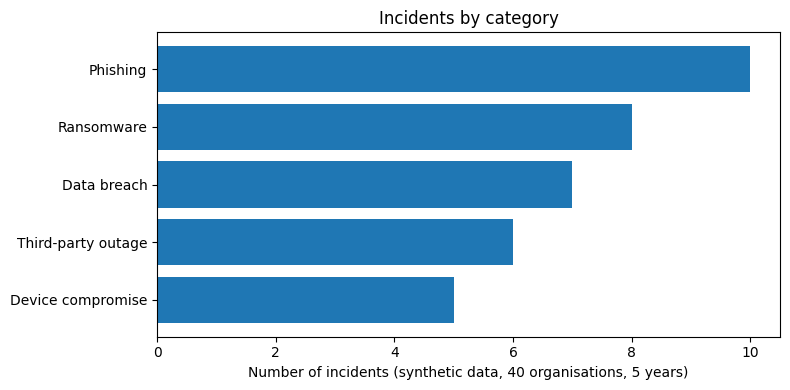

Median severity by category (ordinal data: median, not mean):
category_clean
Data breach             High
Device compromise       High
Phishing                 Low
Ransomware              High
Third-party outage    Medium


In [9]:
counts = data['category_clean'].value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(counts.index[::-1], counts.values[::-1])
ax.set_xlabel(f'Number of incidents (synthetic data, {N_ORGANISATIONS} organisations, {N_YEARS} years)')
ax.set_title('Incidents by category')
finish('p5_fig2_incidents_by_category')

severity_median = data.groupby('category_clean')['severity_clean'].apply(lambda s: s.sort_values().iloc[(len(s) - 1) // 2])
print('Median severity by category (ordinal data: median, not mean):')
print(severity_median.to_string())

In [10]:
cost_stats = data.groupby('category_clean')['cost_clean'].agg(
    Incidents_with_cost='count',
    Median='median',
    Mean='mean',
    Quartile_1=lambda s: s.quantile(0.25),
    Quartile_3=lambda s: s.quantile(0.75),
    Minimum='min',
    Maximum='max',
)
cost_stats['Mean_minus_median'] = cost_stats['Mean'] - cost_stats['Median']
cost_stats

,Incidents_with_cost,Median,Mean,Quartile_1,Quartile_3,Minimum,Maximum,Mean_minus_median
category_clean,,,,,,,,
Data breach,6,"545,000.00","590,000.00","345,000.00","745,000.00","260,000.00","1,100,000.00","45,000.00"
Device compromise,4,"310,000.00","332,500.00","260,000.00","382,500.00","200,000.00","510,000.00","22,500.00"
Phishing,8,"26,500.00","29,250.00","21,000.00","35,250.00","12,000.00","52,000.00","2,750.00"
Ransomware,7,"610,000.00","1,275,714.29","470,000.00","1,100,000.00","380,000.00","4,800,000.00","665,714.29"
Third-party outage,5,"120,000.00","129,000.00","90,000.00","150,000.00","75,000.00","210,000.00","9,000.00"


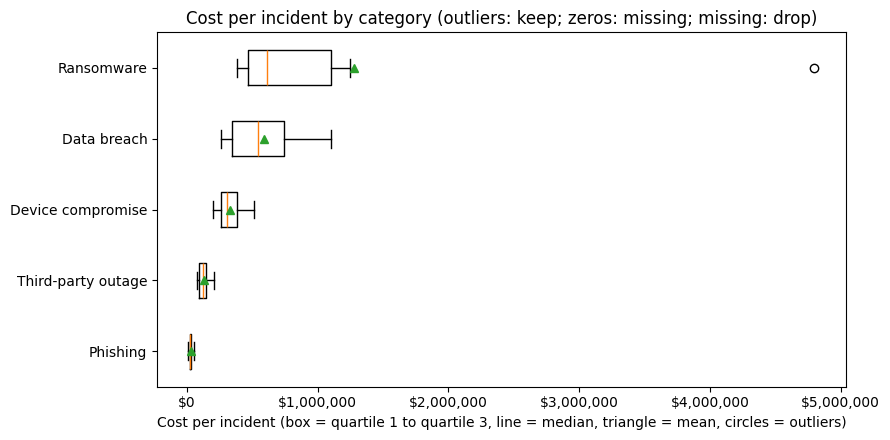

In [11]:
order = cost_stats.sort_values('Median').index.tolist()
groups = [data.loc[(data['category_clean'] == cat) & data['cost_clean'].notna(), 'cost_clean'] for cat in order]

fig, ax = plt.subplots(figsize=(9, 4.5))
try:
    ax.boxplot(groups, orientation='horizontal', showmeans=True)   # newer Matplotlib
except TypeError:
    ax.boxplot(groups, vert=False, showmeans=True)                 # older Matplotlib
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel('Cost per incident (box = quartile 1 to quartile 3, line = median, triangle = mean, circles = outliers)')
ax.set_title(f"Cost per incident by category (outliers: {OUTLIER_RULE}; zeros: {ZERO_COST_RULE}; missing: {MISSING_COST_RULE})")
finish('p5_fig3_cost_by_category')

## 6. From statistics to Assignment 1 inputs

**ARO.** The dataset covers many organisations, so the number of incidents is not an ARO. For one organisation: ARO = incidents ÷ (organisations × years). Getting the denominator right is the difference between a sensible estimate and a wildly wrong one.

**SLE.** Use the quartiles as a low / likely / high range: quartile 1, median, quartile 3. This is the same kind of range you built by judgement in Practical 4, but now it comes from data.

The table is also saved as `p5_risk_inputs.csv`.

In [12]:
inputs = pd.DataFrame({
    'Incidents': data['category_clean'].value_counts(),
})
inputs['ARO_per_organisation'] = inputs['Incidents'] / (N_ORGANISATIONS * N_YEARS)
inputs['SLE_low_Q1'] = cost_stats['Quartile_1']
inputs['SLE_likely_median'] = cost_stats['Median']
inputs['SLE_high_Q3'] = cost_stats['Quartile_3']
inputs['ALE_low'] = inputs['ARO_per_organisation'] * inputs['SLE_low_Q1']
inputs['ALE_likely'] = inputs['ARO_per_organisation'] * inputs['SLE_likely_median']
inputs['ALE_high'] = inputs['ARO_per_organisation'] * inputs['SLE_high_Q3']
inputs['ALE_if_mean_used'] = inputs['ARO_per_organisation'] * cost_stats['Mean']
if SAVE_FIGURES:
    inputs.to_csv('p5_risk_inputs.csv')
inputs = inputs.sort_values('ALE_likely', ascending=False)
print('ARO per organisation (3 decimal places):')
print(inputs['ARO_per_organisation'].map('{:.3f}'.format).to_string())
inputs.drop(columns=['ARO_per_organisation'])

ARO per organisation (3 decimal places):
category_clean
Ransomware            0.040
Data breach           0.035
Device compromise     0.025
Third-party outage    0.030
Phishing              0.050


,Incidents,SLE_low_Q1,SLE_likely_median,SLE_high_Q3,ALE_low,ALE_likely,ALE_high,ALE_if_mean_used
category_clean,,,,,,,,
Ransomware,8,"470,000.00","610,000.00","1,100,000.00","18,800.00","24,400.00","44,000.00","51,028.57"
Data breach,7,"345,000.00","545,000.00","745,000.00","12,075.00","19,075.00","26,075.00","20,650.00"
Device compromise,5,"260,000.00","310,000.00","382,500.00","6,500.00","7,750.00","9,562.50","8,312.50"
Third-party outage,6,"90,000.00","120,000.00","150,000.00","2,700.00","3,600.00","4,500.00","3,870.00"
Phishing,10,"21,000.00","26,500.00","35,250.00","1,050.00","1,325.00","1,762.50","1,462.50"


## 7. Questions (answer in your worksheet)

1. In Section 2, which statistics barely changed when 0 and 200 were added, and which changed a lot?
2. For ransomware, how far apart are the mean and the median cost? Which would you report to management as the 'typical' cost, and why?
3. Change `OUTLIER_RULE` and run again. What happens to the ransomware mean, median, and `ALE_if_mean_used`?
4. Change `ZERO_COST_RULE` to `'keep'`. Which category is affected, and is a zero-cost phishing incident believable?
5. What would you have to disclose in a report if you used these figures?

## DJI case bridge: applying the results responsibly

Use this section when transferring the notebook exercise to the Week 5 worksheet and the continuing DJI case study.

| DJI risk from Practical 2 | Closest category in this teaching dataset | How to interpret the match |
|---|---|---|
| **R7 — Credential stuffing leading to customer-account takeover** | **Phishing** | The raw data includes a record labelled `Phishing / account takeover`, which the standardisation function maps to `Phishing`. This is the closest available proxy, but credential stuffing is not the same attack as phishing. |
| **R3 — FlightHub administrator credential compromise and fleet-data exposure** | **Data breach** | This category may help describe the cost of a data-exposure outcome, but it does not isolate privileged-account compromise as the initial event. |
| **R1 — GPS spoofing and possible drone safety incident** | **No direct equivalent** | `Device compromise` is not a reliable substitute for GPS spoofing or a flight-safety incident. Do not claim that its frequency or costs represent R1. |

### Suggested choice for Practical 5, Part 4

If you need to choose one category to discuss alongside one of your three risks, **Phishing is a defensible illustrative analogue for R7**, because the synthetic records explicitly include a combined `Phishing / account takeover` label. State that the match is imperfect and is used only to practise the method.

Under the default settings (`ZERO_COST_RULE = 'missing'`, `MISSING_COST_RULE = 'drop'`, `OUTLIER_RULE = 'keep'`), use the `Phishing` row in Section 6 to copy the dataset-derived incident count, ARO per organisation, SLE Q1 / median / Q3, ALE range, and `ALE_if_mean_used` into the worksheet. These outputs describe this synthetic dataset only. They **must not replace** the DJI assessment estimates in Practical 3 or be presented as verified DJI rates.

### What to disclose in Assignment 1

- The notebook dataset is synthetic and covers a hypothetical sample of 40 organisations over five years.
- The chosen category is only an imperfect proxy for a DJI risk; the attack mechanisms and population may differ.
- The denominator is `40 organisations × 5 years`, so an incident count is not itself an ARO for one organisation.
- The low / likely / high loss figures are the first and third quartiles and median of the cleaned category costs, not confidence intervals.
- Your selected cleaning settings affect the result; retain the cleaning log and explain why the final settings are defensible.
- Actual DJI ARO and SLE would require appropriately scoped, validated incident records and cost data.